# The threshold: R0, the herd threshold and immunisation on the baked cases

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 and 02 of topic 01-getting-started
- **Reading time:** about 15 minutes

## Objectives

By the end of this notebook you can:

- compute $R_0$ and the herd threshold $1 - 1/R_0$ for each baked case;
- explain why a case with $R_0 \le 1$ has no threshold to cross;
- run the engine with part of the population immunised and see the outbreak fade above the threshold.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and prints their versions.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json

import numpy as np
import matplotlib.pyplot as plt

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


The engine is imported from `data-pipeline/` by its path, as in topic 01.

In [2]:
# The notebook sits three folders below the repository root; the pipeline's modules are imported by their path
import sys
from pathlib import Path

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.sir import simulate
from pipeline.io.schema import SIRParams

print(simulate.__module__, SIRParams.__module__)

pipeline.model.sir pipeline.io.schema


## Data

The parameters of the five baked cases.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json`.

The next cell defines the readers and lists the cases.

In [3]:
# Two readers of the committed artifacts: a missing file stops the notebook and names its path
def read_json(relative):
    return json.loads((ROOT / "data" / "derived" / relative).read_text(encoding="utf-8"))


def params_of(case_id):
    p = read_json(f"manifests/{case_id}.json")["params"]
    return SIRParams(case_id, p["beta"], p["gamma"], p["N"], p["I0"], p["days"])


CASES = [c["case_id"] for c in read_json("manifests/index.json")["cases"]]
OUTBREAKS = [c for c in CASES if c.startswith("EX")]
SUPERCRITICAL = [c for c in OUTBREAKS if params_of(c).beta > params_of(c).gamma]
print(CASES)
print("cases that can take off:", SUPERCRITICAL)

['CTRL_degenerate', 'EX01_subcritical', 'EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']
cases that can take off: ['EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']


## Method

$R_0 = \beta / \gamma$ is the basic reproduction ratio (Diekmann, Heesterbeek and Metz, 1990). When a fraction $v$ of the population is immune at the start, one infected person meets susceptible people only a fraction $1 - v$ of the time, so the effective ratio is $R_0 (1 - v)$. The outbreak cannot grow when this is below 1, that is when

$$v > 1 - \frac{1}{R_0}$$

This is the herd threshold of Diekmann, Heesterbeek and Metz (1990). For $R_0 \le 1$ the right side is not positive: there is nothing to immunise. The next cell computes the ratio and the threshold for every case.

In [4]:
# R0 and the herd threshold of every baked case
for case_id in CASES:
    p = params_of(case_id)
    r0 = p.beta / p.gamma
    threshold = f"{1 - 1 / r0:.3f}" if r0 > 1 else "none (R0 <= 1)"
    print(f"{case_id:18s} R0={r0:5.2f}  herd threshold: {threshold}")

CTRL_degenerate    R0= 2.00  herd threshold: 0.500
EX01_subcritical   R0= 0.72  herd threshold: none (R0 <= 1)
EX02_epidemic      R0= 2.75  herd threshold: 0.636
EX03_fast_burn     R0= 6.00  herd threshold: 0.833
EX04_slow_spread   R0= 1.20  herd threshold: 0.167


To test the threshold with the engine, immunise a fraction $v$ of the population at the start. The engine takes no immunity parameter, so the cell uses an exact equivalence: a population $N(1-v)$ with contact rate $\beta(1-v)$ has the same rate of new infections, $\beta (1-v) S I / (N (1-v)) = \beta S I / N$, and the same susceptible people at the start, as the full population with a fraction $v$ immune. The attack rate is then divided back to the full population. The cell runs the epidemic case with 0%, 30%, 60% and 70% immunised; its threshold is the one printed above.

v=0.0  R0_eff=2.75  peak infected=  27345.2  infected overall=0.9237
v=0.3  R0_eff=1.92  peak infected=   9957.7  infected overall=0.5446
v=0.6  R0_eff=1.10  peak infected=    216.4  infected overall=0.0496
v=0.7  R0_eff=0.83  peak infected=     50.0  infected overall=0.0028


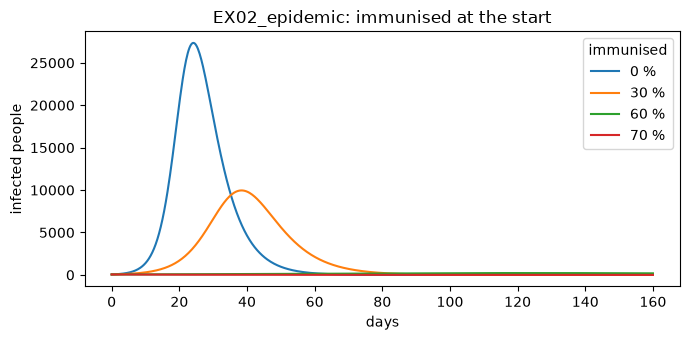

In [5]:
# Run the epidemic case with a fraction v immune at the start, through the equivalent parameters
p = params_of("EX02_epidemic")
coverages = [0.0, 0.3, 0.6, 0.7]
runs = {}
for v in coverages:
    scaled = SIRParams(p.case_id, p.beta * (1 - v), p.gamma, p.N * (1 - v), p.I0, p.days)
    runs[v] = simulate(scaled)
    share = runs[v].R[-1] / p.N
    print(f"v={v:.1f}  R0_eff={p.beta / p.gamma * (1 - v):.2f}  peak infected={runs[v].peak_I:9.1f}  infected overall={share:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
for v, r in runs.items():
    ax.plot(r.t, r.I, label=f"{int(v * 100)} %")
ax.set_xlabel("days")
ax.set_ylabel("infected people")
ax.set_title("EX02_epidemic: immunised at the start")
ax.legend(title="immunised")
fig.tight_layout()
plt.show()

## Results

The table lists R0 and the herd threshold per case: the epidemic case needs about 64% of the population immune, the fast-burn case about 83%, the slow-spread case only about 17%, and the sub-critical case and the control have no threshold to cross. The second table and the figure run the epidemic case: with 0% and 30% immunised the outbreak still happens, with a lower and later peak; at 60%, just under the threshold, the effective ratio is just above 1 and the outbreak is small and slow; at 70%, above the threshold, the effective ratio is below 1, the infected people never rise above the initial ones and the epidemic fades. What these runs do not show is the exact size of the outbreak near the threshold: the next notebook solves the final size.

## Summary

- $R_0 = \beta / \gamma$ decides growth; the herd threshold is $1 - 1/R_0$ when $R_0 > 1$.
- An immune fraction above the threshold keeps the effective ratio below 1 and the outbreak fades.
- Next: notebook 02 of this topic solves the final size and compares it with the simulated course.

## References

- Diekmann, O., Heesterbeek, J. A. P. and Metz, J. A. J. (1990). On the definition and the computation of the basic reproduction ratio R0 in models for infectious diseases in heterogeneous populations. Journal of Mathematical Biology. https://doi.org/10.1007/BF00178324
- van den Driessche, P. and Watmough, J. (2002). Reproduction numbers and sub-threshold endemic equilibria for compartmental models of disease transmission. Mathematical Biosciences. https://doi.org/10.1016/S0025-5564(02)00108-6
- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine and the cases of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).

What each work is credited with is what the research basis of the SDD (`docs/design/SDD.md`) records; the text of their pages was not re-read, only their Crossref records.